In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
data = pd.read_csv("data/data_preprocessed.csv")
print("Shape du dataset :", data.shape)

Shape du dataset : (357952, 92)


Tri temporel et découpage Train / Validation / Test

In [42]:
data_processed = data.sort_values(by="time_of_day")

# 70% / 15% / 15%
train_size = int(len(data_processed) * 0.7)
val_size   = int(len(data_processed) * 0.15)

train_data = data_processed.iloc[:train_size]
val_data   = data_processed.iloc[train_size:train_size + val_size]
test_data  = data_processed.iloc[train_size + val_size:]


Séparation des features et des labels

In [43]:
X_train = train_data.drop(columns=["normality"])
y_train = train_data["normality"]

X_val = val_data.drop(columns=["normality"])
y_val = val_data["normality"]

X_test = test_data.drop(columns=["normality"])
y_test = test_data["normality"]


Entraînement du Random Forest

In [44]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

Prédictions sur le jeu de validation

In [46]:
y_val_pred = rf.predict(X_val)
y_val_proba = rf.predict_proba(X_val)[:, 1]

print(classification_report(y_val, y_val_pred))
print("ROC-AUC Validation :", roc_auc_score(y_val, y_val_proba))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98     51124
           1       1.00      0.16      0.27      2568

    accuracy                           0.96     53692
   macro avg       0.98      0.58      0.63     53692
weighted avg       0.96      0.96      0.95     53692

ROC-AUC Validation : 0.998403905896384


Matrice de confusion (Validation)

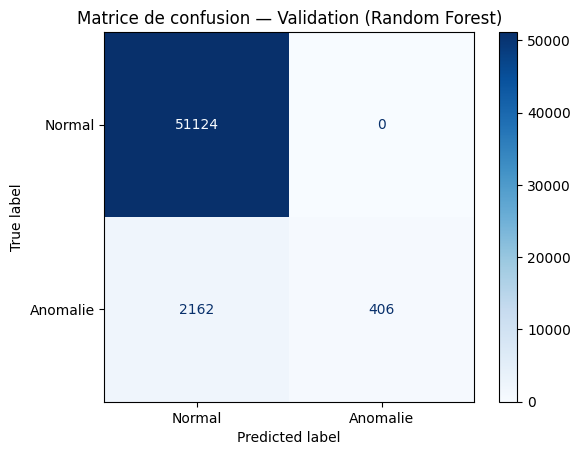

In [47]:
cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Anomalie"]
)

disp.plot(cmap="Blues")
plt.title("Matrice de confusion — Validation (Random Forest)")
plt.show()

Courbe ROC (Validation)

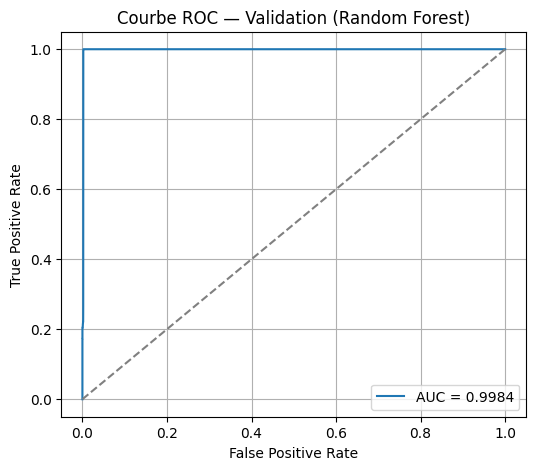

In [48]:
fpr, tpr, thresholds = roc_curve(y_val, y_val_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_val, y_val_proba):.4f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Courbe ROC — Validation (Random Forest)")
plt.legend()
plt.grid(True)
plt.show()